

> Q. Iris Dataset Classification using Random Forest



In [7]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [8]:
iris = load_iris()
X = iris.data
y = iris.target

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=3)
model.fit(X_train, y_train)



RandomForestClassifier(max_depth=3, random_state=42)

In a Jupyter environment, please rerun this cell to show the HTML representation or trust the notebook.
On GitHub, the HTML representation is unable to render, please try loading this page with nbviewer.org.

In [10]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1 Score: {f1 * 100:.2f}%")

print("\nFeature Importances:")
for feat,imp in zip(iris.feature_names, model.feature_importances_):
    print(f"{feat}: {imp * 100:.2f}%")

Accuracy: 96.67%
Precision: 96.97%
Recall: 96.67%
F1 Score: 96.66%

Feature Importances:
sepal length (cm): 11.43%
sepal width (cm): 0.58%
petal length (cm): 44.03%
petal width (cm): 43.96%


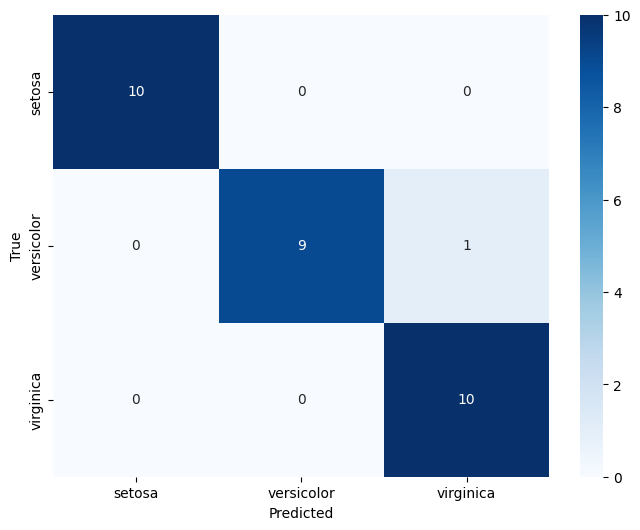

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xticks([0.5,1.5,2.5], iris.target_names)
plt.yticks([0.5,1.5,2.5], iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
